# Lab 13 (Week 3 — Lab 3): Convolutional Neural Networks (CNNs)

Welcome to Lab 13! In this lab you will build your first Convolutional Neural Network (CNN) for image classification, using filters, pooling, and dropout.

**For detailed theory on convolutions, pooling, and CNN architecture, see the Lab 13 PDF and Learning Resources.**

This notebook focuses on the practical, hands-on workflow.

**Instructions:**
- Write your code between the `### YOUR CODE HERE ###` and `### END ###` markers.
- Run each cell with **Shift + Enter**.
- Compare your output with the **Expected Output** shown below each exercise where provided.
- Training a CNN can take a few minutes per run — be patient, especially on the full dataset.

## Getting the Dataset

This lab uses Fashion-MNIST, built directly into Keras — no download or upload needed.

In [1]:
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt

(X_train, y_train), (X_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

print("Training data shape:", X_train.shape)
print("Test data shape:", X_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training data shape: (60000, 28, 28)
Test data shape: (10000, 28, 28)


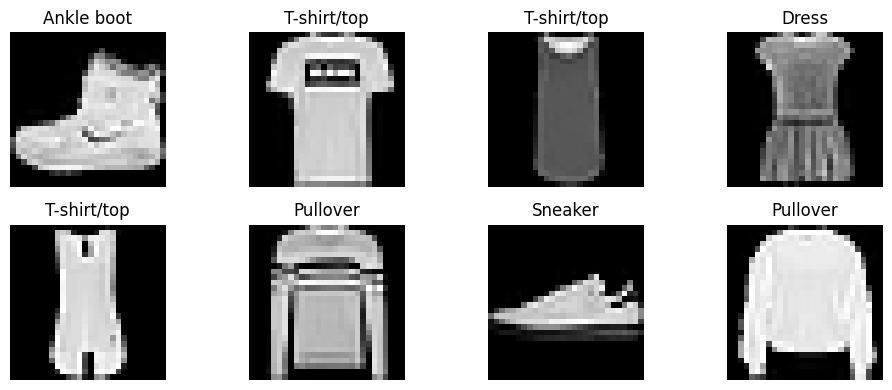

In [2]:
# Look at a few sample images
plt.figure(figsize=(10, 4))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()

## Preparing the Data

Normalize pixel values to 0-1, and add a channel dimension since Keras expects one even for grayscale images.

In [3]:
X_train_prepared = X_train.astype("float32") / 255.0
X_test_prepared = X_test.astype("float32") / 255.0

X_train_prepared = X_train_prepared.reshape(-1, 28, 28, 1)
X_test_prepared = X_test_prepared.reshape(-1, 28, 28, 1)

print("Prepared training shape:", X_train_prepared.shape)

Prepared training shape: (60000, 28, 28, 1)


## Example 1: Building a CNN

In [4]:
from tensorflow.keras import layers

model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

## Example 2: Compiling & Training

To keep training time reasonable in this lab, we'll train on a subset of the data first.

In [5]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    X_train_prepared[:10000], y_train[:10000],
    epochs=8,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

Epoch 1/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 11s 75ms/step - accuracy: 0.6086 - loss: 1.0981 - val_accuracy: 0.7650 - val_loss: 0.6401
Epoch 2/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 8s 60ms/step - accuracy: 0.7625 - loss: 0.6526 - val_accuracy: 0.7880 - val_loss: 0.5419
Epoch 3/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 8s 65ms/step - accuracy: 0.7929 - loss: 0.5695 - val_accuracy: 0.8150 - val_loss: 0.4911
Epoch 4/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 9s 70ms/step - accuracy: 0.8159 - loss: 0.5153 - val_accuracy: 0.8185 - val_loss: 0.4817
Epoch 5/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 54ms/step - accuracy: 0.8276 - loss: 0.4782 - val_accuracy: 0.8225 - val_loss: 0.4571
Epoch 6/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 11s 61ms/step - accuracy: 0.8436 - loss: 0.4425 - val_accuracy: 0.8500 - val_loss: 0.4236
Epoch 7/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 9s 71ms/step - accuracy: 0.8560 - loss: 0.4110 - val_accuracy: 0.8510 - val_loss: 0.4198
Epoch 8/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 56ms/step - accuracy: 0.8561 - loss: 0.3994 - val_accuracy: 

## Example 3: Visualizing Training Progress

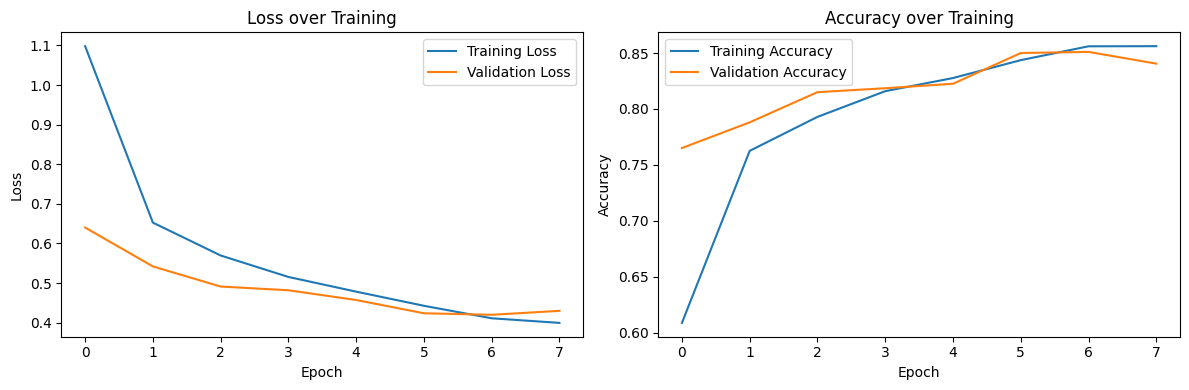

In [6]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Loss over Training")

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.title("Accuracy over Training")

plt.tight_layout()
plt.show()

## Example 4: Evaluating and Viewing Predictions

Test Accuracy: 0.8434


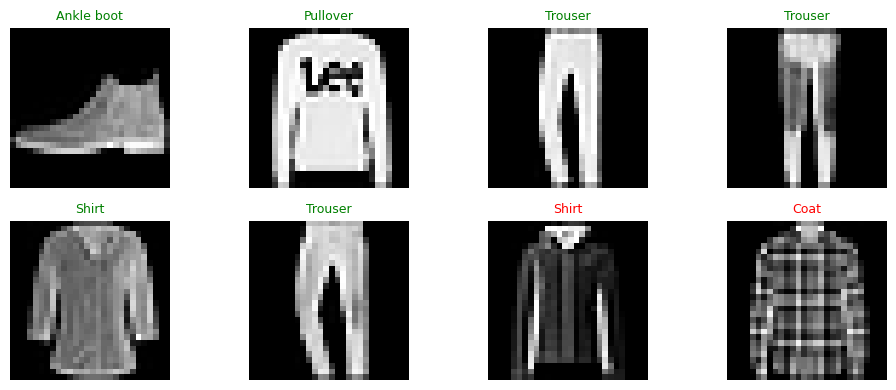

In [7]:
test_loss, test_accuracy = model.evaluate(X_test_prepared, y_test, verbose=0)
print(f"Test Accuracy: {test_accuracy:.4f}")

predictions = model.predict(X_test_prepared[:8], verbose=0)
predicted_labels = predictions.argmax(axis=1)

plt.figure(figsize=(10, 4))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(X_test[i], cmap="gray")
    correct = predicted_labels[i] == y_test[i]
    color = "green" if correct else "red"
    plt.title(f"{class_names[predicted_labels[i]]}", color=color, fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

## Practice Exercise 1: Adding a Third Convolutional Block

**Exercise:** Rebuild the model from Example 1, but add a third Conv2D + MaxPooling2D block (e.g., 128 filters) before the Flatten layer. Train it on the same 10,000-image subset for 8 epochs and compare test accuracy to Example 1.

In [8]:
model_deeper = None
test_accuracy_deeper = None

### YOUR CODE HERE ###
model_deeper = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax")
])

model_deeper.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_deeper = model_deeper.fit(
    X_train_prepared[:10000],
    y_train[:10000],
    epochs=8,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

test_loss_deeper, test_accuracy_deeper = model_deeper.evaluate(
    X_test_prepared, y_test, verbose=0
)

print("Original CNN accuracy:", test_accuracy)
### END ###

print("Test accuracy (deeper CNN):", test_accuracy_deeper)

Epoch 1/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 17s 116ms/step - accuracy: 0.5583 - loss: 1.2533 - val_accuracy: 0.7175 - val_loss: 0.7421
Epoch 2/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 16s 83ms/step - accuracy: 0.7335 - loss: 0.7417 - val_accuracy: 0.7655 - val_loss: 0.6376
Epoch 3/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 10s 81ms/step - accuracy: 0.7663 - loss: 0.6401 - val_accuracy: 0.7750 - val_loss: 0.5765
Epoch 4/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 9s 71ms/step - accuracy: 0.7916 - loss: 0.5756 - val_accuracy: 0.7955 - val_loss: 0.5599
Epoch 5/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 11s 76ms/step - accuracy: 0.8073 - loss: 0.5323 - val_accuracy: 0.8030 - val_loss: 0.5279
Epoch 6/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 11s 89ms/step - accuracy: 0.8192 - loss: 0.5051 - val_accuracy: 0.8080 - val_loss: 0.4979
Epoch 7/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 17s 64ms/step - accuracy: 0.8263 - loss: 0.4826 - val_accuracy: 0.8220 - val_loss: 0.4817
Epoch 8/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 10s 66ms/step - accuracy: 0.8380 - loss: 0.4499 - val_accu

## Practice Exercise 2: Changing the Dropout Rate

**Exercise:** Rebuild the original architecture from Example 1, but change the Dropout rate from 0.3 to 0.5. Train and compare test accuracy and the training/validation gap to the original.

In [9]:
### YOUR CODE HERE ###
model_dropout = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax")
])

model_dropout.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_dropout = model_dropout.fit(
    X_train_prepared[:10000],
    y_train[:10000],
    epochs=8,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

test_loss_dropout, test_accuracy_dropout = model_dropout.evaluate(
    X_test_prepared, y_test, verbose=0
)

print("Original test accuracy:", test_accuracy)
print("Dropout 0.5 test accuracy:", test_accuracy_dropout)

print(
    "Original final training/validation accuracy:",
    history.history["accuracy"][-1],
    history.history["val_accuracy"][-1]
)

print(
    "Dropout 0.5 final training/validation accuracy:",
    history_dropout.history["accuracy"][-1],
    history_dropout.history["val_accuracy"][-1]
)
### END ###

Epoch 1/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 10s 71ms/step - accuracy: 0.5552 - loss: 1.2933 - val_accuracy: 0.7555 - val_loss: 0.7075
Epoch 2/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 10s 70ms/step - accuracy: 0.7286 - loss: 0.7784 - val_accuracy: 0.7755 - val_loss: 0.5719
Epoch 3/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 57ms/step - accuracy: 0.7549 - loss: 0.6679 - val_accuracy: 0.7935 - val_loss: 0.5451
Epoch 4/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 9s 69ms/step - accuracy: 0.7736 - loss: 0.6177 - val_accuracy: 0.8170 - val_loss: 0.5000
Epoch 5/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 10s 76ms/step - accuracy: 0.7925 - loss: 0.5737 - val_accuracy: 0.8150 - val_loss: 0.4896
Epoch 6/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 9s 68ms/step - accuracy: 0.8004 - loss: 0.5465 - val_accuracy: 0.8320 - val_loss: 0.4630
Epoch 7/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 11s 72ms/step - accuracy: 0.8110 - loss: 0.5258 - val_accuracy: 0.8335 - val_loss: 0.4544
Epoch 8/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 10s 73ms/step - accuracy: 0.8183 - loss: 0.5003 - val_accurac

## Practice Exercise 3: Viewing Misclassified Images

**Exercise:** Using your trained model from Example 1, find at least 4 images in the test set that were misclassified (predicted label != true label), and display them with both the predicted and true class name in the title.

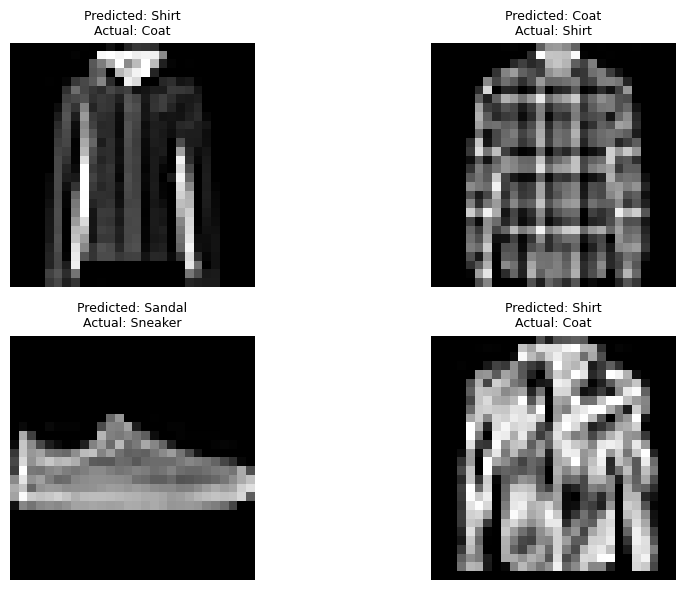

Misclassified images displayed: 4


In [10]:
### YOUR CODE HERE ###
predictions_all = model.predict(X_test_prepared, verbose=0)
predicted_labels_all = predictions_all.argmax(axis=1)

shown = 0

plt.figure(figsize=(10, 6))

for i in range(len(y_test)):
    if predicted_labels_all[i] != y_test[i] and shown < 4:
        plt.subplot(2, 2, shown + 1)
        plt.imshow(X_test[i], cmap="gray")

        plt.title(
            f"Predicted: {class_names[predicted_labels_all[i]]}\n"
            f"Actual: {class_names[y_test[i]]}",
            fontsize=9
        )

        plt.axis("off")
        shown = shown + 1

plt.tight_layout()
plt.show()

print("Misclassified images displayed:", shown)
### END ###

## Lab Tasks

Complete the following in this notebook, below this cell.

1. **Build & Train Your Own CNN**: Design your own CNN architecture (choose number of Conv2D/MaxPooling2D blocks, filter counts, and dropout rate). Train it on at least 10,000 training images and report test accuracy.
2. **Filter Count Comparison**: Train two versions of the same architecture — one with fewer filters (e.g., 16, 32) and one with more filters (e.g., 64, 128) in the Conv2D layers. Compare test accuracy and training time between them.
3. **Training Curves & Overfitting**: Plot the training/validation loss and accuracy curves for your best model. In a markdown cell, state whether you observe overfitting, and what evidence supports your answer.
4. **Per-Class Performance**: Using `sklearn.metrics.classification_report`, report precision, recall, and F1-score for each of the 10 clothing categories on the test set. Which category does your model struggle with most?
5. **Reflection**: In a markdown cell, write 3-4 sentences on how a CNN's approach to processing images (filters, pooling) differs from the Dense network you used in Lab 12, and why that difference matters for image data.

In [11]:
# Task 1

import time

model_small = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(16, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax")
])

model_small.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

start_small = time.process_time()

history_small = model_small.fit(
    X_train_prepared[:12500],
    y_train[:12500],
    epochs=8,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

cpu_time_small = time.process_time() - start_small

loss_small, accuracy_small = model_small.evaluate(
    X_test_prepared, y_test, verbose=0
)

print("Test accuracy:", accuracy_small)
print("Training CPU time in seconds:", cpu_time_small)

Epoch 1/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 8s 39ms/step - accuracy: 0.5904 - loss: 1.1536 - val_accuracy: 0.7580 - val_loss: 0.6642
Epoch 2/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 30ms/step - accuracy: 0.7507 - loss: 0.6662 - val_accuracy: 0.7904 - val_loss: 0.5563
Epoch 3/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 7s 41ms/step - accuracy: 0.7874 - loss: 0.5824 - val_accuracy: 0.8148 - val_loss: 0.4951
Epoch 4/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 10s 37ms/step - accuracy: 0.8048 - loss: 0.5280 - val_accuracy: 0.8200 - val_loss: 0.4664
Epoch 5/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 9s 31ms/step - accuracy: 0.8211 - loss: 0.4936 - val_accuracy: 0.8408 - val_loss: 0.4533
Epoch 6/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 7s 42ms/step - accuracy: 0.8303 - loss: 0.4692 - val_accuracy: 0.8496 - val_loss: 0.4252
Epoch 7/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 30ms/step - accuracy: 0.8440 - loss: 0.4352 - val_accuracy: 0.8532 - val_loss: 0.4032
Epoch 8/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 10s 59ms/step - accuracy: 0.8513 - loss: 0.4123 - val_accuracy: 

In [12]:
# Task 2

model_large = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax")
])

model_large.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

start_large = time.process_time()

history_large = model_large.fit(
    X_train_prepared[:12500],
    y_train[:12500],
    epochs=8,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

cpu_time_large = time.process_time() - start_large

loss_large, accuracy_large = model_large.evaluate(
    X_test_prepared, y_test, verbose=0
)

print("Filters 16, 32:")
print("Test accuracy:", accuracy_small)
print("Training CPU seconds:", cpu_time_small)

print("\nFilters 64, 128:")
print("Test accuracy:", accuracy_large)
print("Training CPU seconds:", cpu_time_large)

Epoch 1/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 33s 201ms/step - accuracy: 0.6769 - loss: 0.8929 - val_accuracy: 0.8044 - val_loss: 0.5496
Epoch 2/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 34s 156ms/step - accuracy: 0.7937 - loss: 0.5579 - val_accuracy: 0.8428 - val_loss: 0.4443
Epoch 3/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 40s 151ms/step - accuracy: 0.8239 - loss: 0.4786 - val_accuracy: 0.8508 - val_loss: 0.4092
Epoch 4/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 25s 159ms/step - accuracy: 0.8464 - loss: 0.4277 - val_accuracy: 0.8532 - val_loss: 0.3980
Epoch 5/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 43s 172ms/step - accuracy: 0.8587 - loss: 0.3858 - val_accuracy: 0.8700 - val_loss: 0.3593
Epoch 6/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 39s 157ms/step - accuracy: 0.8714 - loss: 0.3599 - val_accuracy: 0.8752 - val_loss: 0.3456
Epoch 7/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 25s 161ms/step - accuracy: 0.8770 - loss: 0.3392 - val_accuracy: 0.8716 - val_loss: 0.3447
Epoch 8/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 39s 152ms/step - accuracy: 0.8834 - loss: 0.3126 - 

I compared two CNNs using the same layer structure, dropout, training images, epochs and batch size. The smaller model achieved 84.72% test accuracy using 67.71 CPU seconds, while the larger model achieved 87.68% using 305.57 CPU seconds. The larger model improved accuracy by 2.96 percentage points but used about 4.5 times as much CPU time. For this run, the smaller model offered a quicker option, while the larger model gave better accuracy.

Selected model: filters 64, 128


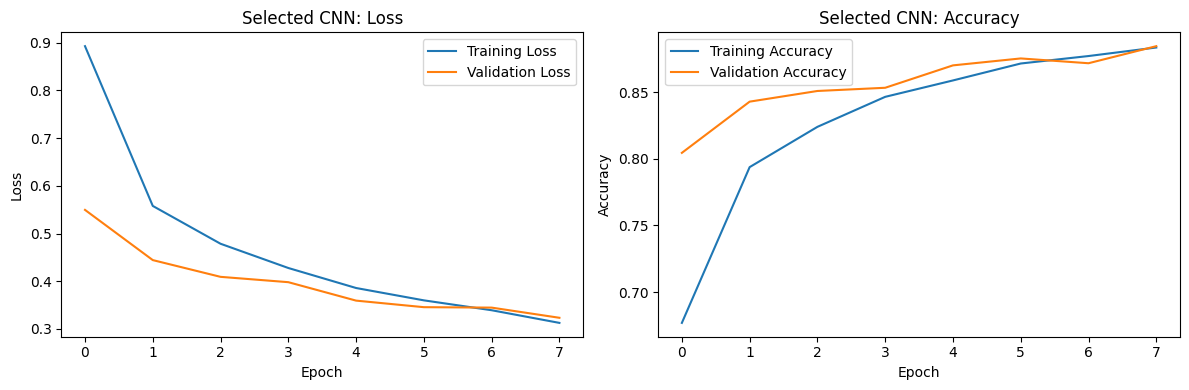

In [13]:
# Task 3

if accuracy_small >= accuracy_large:
    best_model = model_small
    best_history = history_small
    print("Selected model: filters 16, 32")
else:
    best_model = model_large
    best_history = history_large
    print("Selected model: filters 64, 128")

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(best_history.history["loss"], label="Training Loss")
plt.plot(best_history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Selected CNN: Loss")

plt.subplot(1, 2, 2)
plt.plot(best_history.history["accuracy"], label="Training Accuracy")
plt.plot(best_history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.title("Selected CNN: Accuracy")

plt.tight_layout()
plt.show()


Training and validation loss both decrease across the eight epochs and finish close together. Both accuracy curves also improve and end at around 88%. I do not see a clear sign of overfitting because validation loss does not consistently rise while training loss falls. This describes the eight epochs shown; training for longer could change the pattern.

In [14]:
# Task 4

from sklearn.metrics import classification_report

best_predictions = best_model.predict(
    X_test_prepared,
    verbose=0
)

best_labels = best_predictions.argmax(axis=1)

print(
    classification_report(
        y_test,
        best_labels,
        target_names=class_names
    )
)

              precision    recall  f1-score   support

 T-shirt/top       0.84      0.80      0.82      1000
     Trouser       0.99      0.96      0.98      1000
    Pullover       0.79      0.83      0.81      1000
       Dress       0.86      0.89      0.88      1000
        Coat       0.80      0.79      0.80      1000
      Sandal       0.97      0.97      0.97      1000
       Shirt       0.66      0.65      0.65      1000
     Sneaker       0.93      0.95      0.94      1000
         Bag       0.96      0.97      0.97      1000
  Ankle boot       0.97      0.94      0.96      1000

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000



The model struggled most with Shirt, which had the lowest F1-score of 0.65. Its precision was 0.66 and its recall was 0.65, meaning it correctly identified around 65% of actual Shirt images. This suggests shirts were harder for the model to distinguish from the other clothing categories.

_Write your Task 5 reflection here._

In Lab 12, the Dense network worked with a row of measurements. The CNN uses filters to learn local patterns in images and reuses those filters across different positions. Pooling reduces the feature-map size before the Dense layers combine the extracted information for classification. This gives the model a structure suited to nearby pixels and image patterns instead of relying only on fully connected layers.